# Every policy on its own (budget B = 10, null arrival)

Compares the experiments in `configs/all_individual_policy.yaml`: the five centralized policies and the five decentralized utilities (uncoordinated FCFS, served round-robin), run on the same 5 agents with 10 tasks each and the same 3 models. Every task is one model call.

Run the experiments first, from the repo root:

```bash
python -m masbudget configs/all_individual_policy.yaml
```

The newest `results/<experiment>_<timestamp>.json` of each experiment is used. All plotting goes through `masbudget.analysis.PolicyComparison`: pass it any list of metric names.

In [1]:
import os
import sys
from pathlib import Path

# Work from the repo root so results/, configs/ and the masbudget package resolve.
ROOT = Path.cwd() if (Path.cwd() / "masbudget").is_dir() else Path.cwd().parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from masbudget.analysis import PolicyComparison, plot_metrics

%matplotlib inline
pd.set_option("display.precision", 4)

CONFIG = "configs/all_individual_policy.yaml"
REFERENCE = "central_optimal_mckp"  # optimal centralized policy, the yardstick for the optimality gap

## Load results

In [2]:
cmp = PolicyComparison.from_config(CONFIG).with_gap(REFERENCE)
print("Metrics available:", ", ".join(cmp.metrics))
cmp.table()

Metrics available: average_quality, success_rate, social_welfare, total_cost, budget_utilization, jains_fairness, optimality_gap


metric                              average_quality  success_rate  \
paradigm      label                                                 
centralized   optimal_mckp                   0.8161        0.9792   
              cheapest_model                 0.4836        0.3125   
              static_equal_quota             0.8155        0.9583   
              confidence_cascade             0.7767        0.8750   
              predictive_router              0.8160        0.9583   
decentralized best_model                     0.4753        0.5417   
              quasi_linear                   0.7708        0.8750   
              dynamic_shadow_price           0.7408        0.7292   
              marginal_roi_ratio             0.6875        0.5208   
              shapley_budget_share           0.5372        0.6042   

metric                              social_welfare  total_cost  \
paradigm      label                                              
centralized   optimal_mckp                  39.174        6.48   
              cheapest_model                23.213        0.48   
              static_equal_quota            39.144        6.48   
              confidence_cascade            37.280        6.38   
              predictive_router             39.169        6.48   
decentralized best_model                    22.812        6.50   
              quasi_linear                  37.000        6.50   
              dynamic_shadow_price          35.560        6.20   
              marginal_roi_ratio            33.002        2.60   
              shapley_budget_share          25.785        6.50   

metric                              budget_utilization  jains_fairness  \
paradigm      label                                                      
centralized   optimal_mckp                      0.9969          0.9993   
              cheapest_model                    0.0738          0.9929   
              static_equal_quota                0.9969          0.9988   
              confidence_cascade                0.9815          0.9979   
              predictive_router                 0.9969          0.9992   
decentralized best_model                        1.0000          0.9991   
              quasi_linear                      1.0000          0.9998   
              dynamic_shadow_price              0.9538          0.9997   
              marginal_roi_ratio                0.4000          0.9990   
              shapley_budget_share              1.0000          0.9997   

metric                              optimality_gap  
paradigm      label                                 
centralized   optimal_mckp                  0.0000  
              cheapest_model                0.4074  
              static_equal_quota            0.0008  
              confidence_cascade            0.0483  
              predictive_router             0.0001  
decentralized best_model                    0.4177  
              quasi_linear                  0.0555  
              dynamic_shadow_price          0.0923  
              marginal_roi_ratio            0.1576  
              shapley_budget_share          0.3418

## Quality

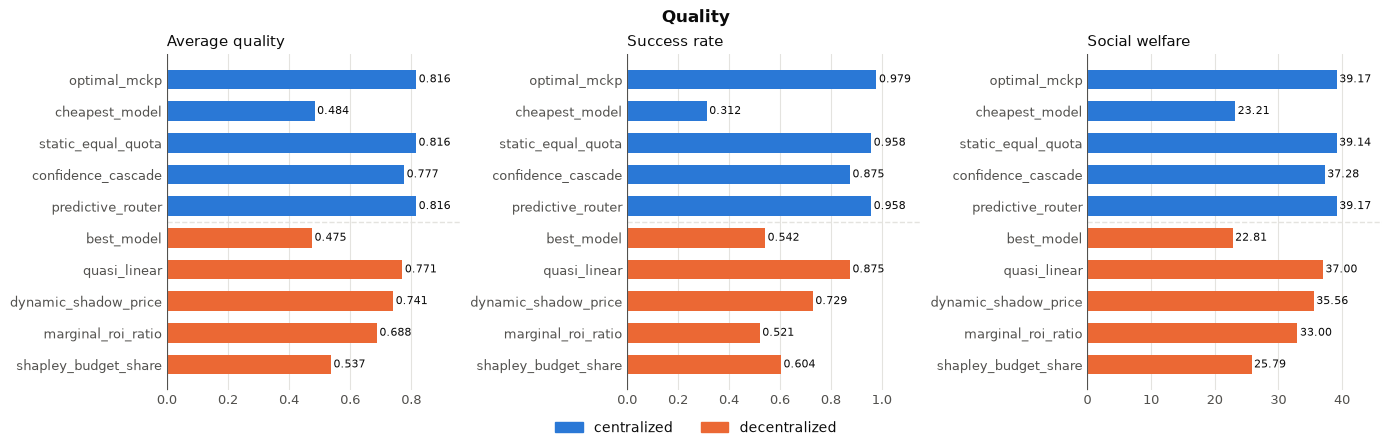

In [3]:
cmp.plot(["average_quality", "success_rate", "social_welfare"], title="Quality")

## Budget (B = 6.5)

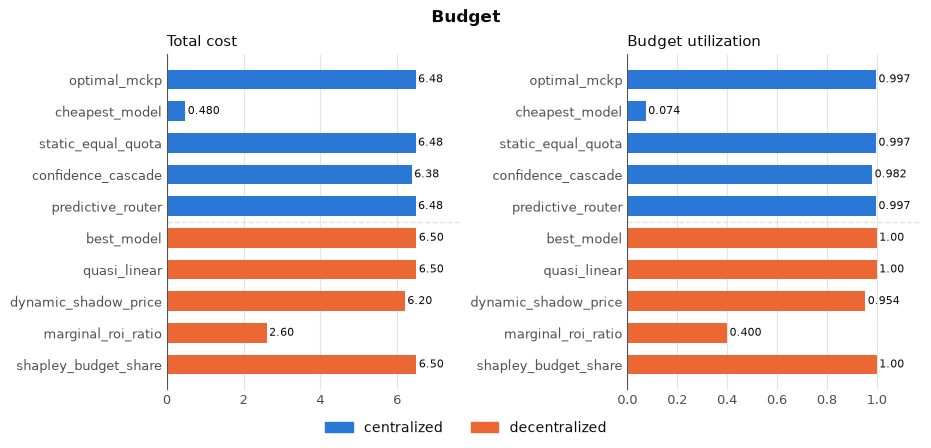

In [4]:
cmp.plot(["total_cost", "budget_utilization"], title="Budget")

## Fairness across the 5 agents

Each agent is scored by the mean quality over its 10 tasks. `starvation_rate` = share of agents with at least one task that got no model; `task_starvation_rate` = share of the 50 tasks that got no model. `first_mover_advantage` (earliest-acting agent vs. latest) only applies to decentralized runs (centralized bars show `n/a`).

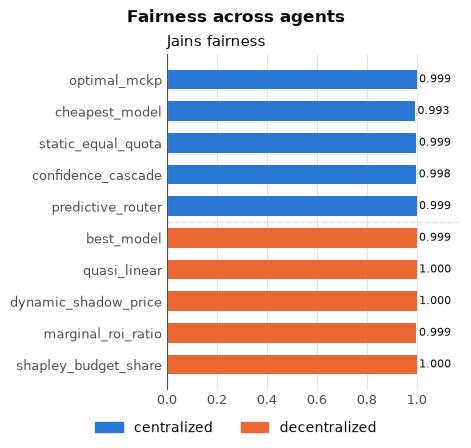

In [6]:
cmp.plot(
    ["jains_fairness"],
    ncols=2,
    title="Fairness across agents",
)

## Optimality gap vs. optimal MCKP

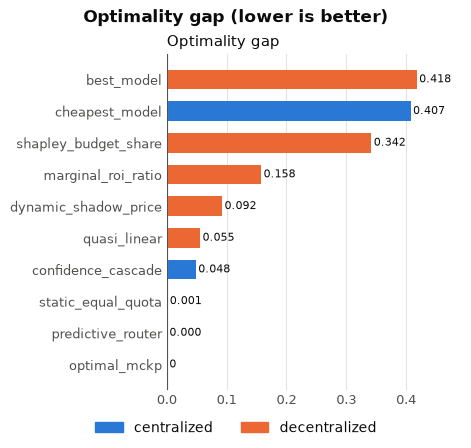

In [7]:
cmp.plot(["optimality_gap"], sort=True, title="Optimality gap (lower is better)")